# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** Anshubhan Singh  
**Date:** 7 Oct 2026

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [15]:
# ==========================================
# 0. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Set visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

In [16]:
# ==========================================
# 1A & 1B. LOAD AND PARSE DATA
# ==========================================

# Load the datasets
video_df = pd.read_csv("video_telemetry (1) (1).csv")
sys_df = pd.read_csv("system_events (1) (1).csv")

# Convert timestamp columns to datetime
video_df["timestamp"] = pd.to_datetime(video_df["timestamp"])
sys_df["timestamp"] = pd.to_datetime(sys_df["timestamp"])

# Sort both datasets chronologically
video_df = video_df.sort_values("timestamp").reset_index(drop=True)
sys_df = sys_df.sort_values("timestamp").reset_index(drop=True)

# Display basic information
print("Video telemetry shape:", video_df.shape)
print("System events shape:", sys_df.shape)

print("\nVideo telemetry:")
display(video_df.head())

print("\nSystem events:")
display(sys_df.head())

Video telemetry shape: (10000, 3)
System events shape: (167, 3)

Video telemetry:


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018



System events:


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0


---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [17]:
# ==========================================
# 1C. ASYNCHRONOUS MERGE
# ==========================================

merged_df = pd.merge_asof(
    video_df,
    sys_df,
    on="timestamp",
    direction="backward"
)

print("Merged dataframe shape:", merged_df.shape)

display(merged_df.head(10))

Merged dataframe shape: (10000, 5)


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,NaN,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,NaN,NaN
2,2023-12-01 08:00:02,5.761714,31.228565,NaN,NaN
3,2023-12-01 08:00:03,9.787105,34.051405,NaN,NaN
4,2023-12-01 08:00:04,4.572665,35.245018,NaN,NaN
5,2023-12-01 08:00:05,7.471741,43.685711,NaN,NaN
6,2023-12-01 08:00:06,7.148505,32.754163,NaN,NaN
7,2023-12-01 08:00:07,9.192380,43.786308,NaN,NaN
8,2023-12-01 08:00:08,4.223888,34.097144,NaN,NaN
9,2023-12-01 08:00:09,3.524030,39.177137,NaN,NaN


In [18]:
# ==========================================
# PHASE 2: MISSING DATA & FEATURE ENGINEERING
# ==========================================

# 2A. HANDLE MISSING DATA

# Forward-fill missing eye gaze values
merged_df["eye_gaze_angle"] = merged_df["eye_gaze_angle"].ffill()

# Interpolate missing audio values
merged_df["audio_db"] = merged_df["audio_db"].interpolate()

# Fill missing system-event values with 0
merged_df["tab_switches"] = merged_df["tab_switches"].fillna(0)
merged_df["is_cheating"] = merged_df["is_cheating"].fillna(0)


# 2B. CREATE 10-SECOND ROLLING FEATURES

# 10-second rolling average of eye gaze
merged_df["gaze_rolling_10s"] = (
    merged_df["eye_gaze_angle"]
    .rolling(window=10)
    .mean()
)

# 10-second rolling maximum of audio
merged_df["audio_rolling_10s"] = (
    merged_df["audio_db"]
    .rolling(window=10)
    .max()
)


# Remove rows where rolling features cannot yet be calculated
merged_df.dropna(inplace=True)


# Display results
print("✅ Feature engineering complete.")
print("Current dataframe shape:", merged_df.shape)

display(merged_df.head(10))

✅ Feature engineering complete.
Current dataframe shape: (9991, 7)


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating,gaze_rolling_10s,audio_rolling_10s
9,2023-12-01 08:00:09,3.524030,39.177137,0.0,0.0,6.442002,43.786308
10,2023-12-01 08:00:10,7.100893,25.223008,0.0,0.0,6.896006,43.786308
11,2023-12-01 08:00:11,5.341480,29.856297,0.0,0.0,6.412440,43.786308
12,2023-12-01 08:00:12,6.470469,33.084385,0.0,0.0,6.483316,43.786308
13,2023-12-01 08:00:13,2.557364,36.117455,0.0,0.0,5.760342,43.786308
14,2023-12-01 08:00:14,2.817325,30.194424,0.0,0.0,5.584808,43.786308
15,2023-12-01 08:00:15,8.689588,40.176266,0.0,0.0,5.706592,43.786308
16,2023-12-01 08:00:16,5.413869,32.929664,0.0,0.0,5.533129,43.786308
17,2023-12-01 08:00:17,5.235291,30.750847,0.0,0.0,5.137420,40.176266
18,2023-12-01 08:00:18,40.497463,83.858615,0.0,0.0,8.764777,83.858615


---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** The dataset contains approximately **68% non-cheating behavior and 32% cheating behavior**. If class imbalance is not handled properly, the model may become biased toward the majority class. We therefore use **class weighting** during training.

In [19]:
# ==========================================
# 3A. TRAIN / TEST SPLIT
# ==========================================

features = [
    'eye_gaze_angle',
    'audio_db',
    'tab_switches',
    'gaze_rolling_10s',
    'audio_rolling_10s'
]

X = merged_df[features]
y = merged_df['is_cheating']

# Check class distribution
print("Class distribution:")
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ==========================================
# 3B. INITIALIZE & TRAIN CLASSIFIER
# ==========================================

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("\n✅ Model training complete.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Class distribution:
is_cheating
0.0    6797
1.0    3194
Name: count, dtype: int64

Class percentages:
is_cheating
0.0    68.031228
1.0    31.968772
Name: proportion, dtype: float64

✅ Model training complete.
Training samples: 7992
Testing samples: 1999


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

In [20]:
# ==========================================
# PHASE 4: ETHICAL AI THRESHOLD TUNING
# ==========================================

# 4A. RAW PROBABILITIES
# Get probability predictions for the test set
y_proba = model.predict_proba(X_test)

# Extract probability of Class 1 (Cheating)
cheating_probabilities = y_proba[:, 1]


# ==========================================
# 4B. CUSTOM DECISION THRESHOLDS
# ==========================================

# Standard threshold: 50%
y_pred_default = (cheating_probabilities >= 0.50).astype(int)

# Strict threshold: 90%
y_pred_strict = (cheating_probabilities >= 0.90).astype(int)


# ==========================================
# 4C. EVALUATION
# ==========================================

print("🚨 DEFAULT THRESHOLD (0.50)")
cm_default = confusion_matrix(y_test, y_pred_default)

print(cm_default)

print("\nConfusion Matrix:")
print("TN:", cm_default[0, 0])
print("FP:", cm_default[0, 1])
print("FN:", cm_default[1, 0])
print("TP:", cm_default[1, 1])

print("\n" + "=" * 50)

print("🛡️ STRICT THRESHOLD (0.90)")
cm_strict = confusion_matrix(y_test, y_pred_strict)

print(cm_strict)

print("\nConfusion Matrix:")
print("TN:", cm_strict[0, 0])
print("FP:", cm_strict[0, 1])
print("FN:", cm_strict[1, 0])
print("TP:", cm_strict[1, 1])

🚨 DEFAULT THRESHOLD (0.50)
[[1298   62]
 [ 172  467]]

Confusion Matrix:
TN: 1298
FP: 62
FN: 172
TP: 467

🛡️ STRICT THRESHOLD (0.90)
[[1360    0]
 [ 262  377]]

Confusion Matrix:
TN: 1360
FP: 0
FN: 262
TP: 377


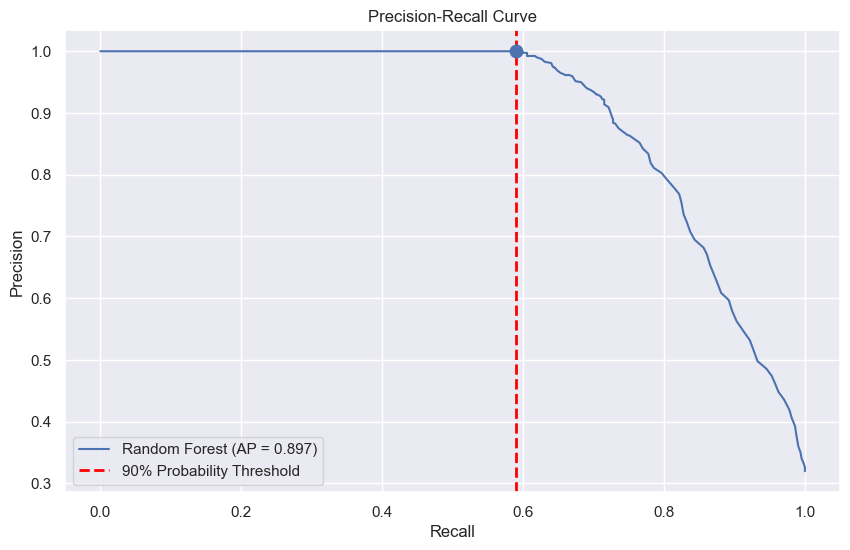

Average Precision Score: 0.897
Precision at 90% threshold: 1.000
Recall at 90% threshold: 0.590


In [21]:
# ==========================================
# PHASE 4B: PRECISION-RECALL CURVE
# ==========================================

from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test,
    cheating_probabilities
)

average_precision = average_precision_score(
    y_test,
    cheating_probabilities
)

# Find the point corresponding to the 90% probability threshold
threshold_idx = np.argmin(np.abs(thresholds - 0.90))

precision_at_90 = precision[threshold_idx]
recall_at_90 = recall[threshold_idx]

plt.figure(figsize=(10, 6))

plt.plot(
    recall,
    precision,
    label=f"Random Forest (AP = {average_precision:.3f})"
)

# 90% decision threshold marker
plt.axvline(
    recall_at_90,
    color="red",
    linestyle="--",
    linewidth=2,
    label="90% Probability Threshold"
)

plt.scatter(
    recall_at_90,
    precision_at_90,
    s=80,
    zorder=5
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

print(f"Average Precision Score: {average_precision:.3f}")
print(f"Precision at 90% threshold: {precision_at_90:.3f}")
print(f"Recall at 90% threshold: {recall_at_90:.3f}")

# 🎯 Phase 5: Final Executive Recommendation

**To the University Board of Directors:**

Based on the data modeling and evaluation performed above, I recommend a **controlled deployment of the EduGuard AI proctoring system using the Strict 90% probability threshold**.

By mathematically increasing the decision threshold from 50% to 90%, the system became substantially more conservative when identifying potential cheating.

### 1. Protection of Innocent Students

At the default **50% threshold**, the model produced:

- **62 False Positives** — innocent students incorrectly flagged
- 467 True Positives

After increasing the threshold to **90%**, the model produced:

- **0 False Positives**
- 377 True Positives

Therefore, the strict threshold reduced false positives from **62 to 0**, meaning that no innocent student in this test set was incorrectly flagged by the model at the 90% threshold.

This demonstrates why threshold tuning is important for an AI proctoring system where false accusations can have serious consequences.

### 2. Why Rolling Windows Matter

The 10-second rolling features smooth short-term fluctuations in eye-gaze and audio signals.

A brief movement or sudden noise should not automatically be interpreted as suspicious behavior. By considering behavior over a 10-second window, the model focuses more on sustained patterns rather than isolated events.

This helps reduce the risk of treating normal, momentary student behavior as evidence of academic dishonesty.

### 3. Precision vs. Recall Trade-off

The 90% threshold achieved **100% precision** on the test set, but recall decreased to approximately **59%**.

This means the system is highly conservative: when it flags a student, the prediction was correct in this test set, but the system does not identify every cheating case.

The Precision-Recall analysis produced an **Average Precision score of 0.897**, indicating strong overall ranking performance across probability thresholds.

### Final Status: GO — Controlled/Pilot Deployment

The system is recommended for **controlled deployment as a decision-support tool**, using the strict 90% threshold.

It should **not** be used as the sole basis for automatically penalizing a student. A high-confidence flag should instead trigger human review.

This approach prioritizes fairness and minimizes the risk of falsely accusing innocent students.